# FedEVT-OSAD: Phase 0 & Phase 1 Complete Pipeline
### Federated Extreme-Value Open-Set Anomaly Detection for Zero-Day Cyberattacks

This notebook provides the **official, standardized Phase 0 and Phase 1 implementation** of the `FedEVT-OSAD` framework.
It addresses and resolves the core architectural vulnerabilities of the base paper (**FP-LSTM**):

| Component | Weakness in Base Paper (FP-LSTM) | FedEVT-OSAD Standardized Solution |
| :--- | :--- | :--- |
| **Zero-Day Protocol** | *Fake Zero-Day*: Evaluated only on seen attack classes | **Leave-One-Family-Out (LOFO)** with 100% holdout of novel attack family |
| **Feature Leakage** | Retained IP/MAC/Port/Timestamp shortcut indicators | **Feature Sanitization**: Strips network identities and target leakage |
| **Heterogeneity** | Vague, untestable non-IID claims | **Dirichlet Partitioning ($\alpha \in [0.1, 10.0]$)** across client nodes |
| **Reconstruction** | *Polluted AE*: Autoencoder trained on all traffic (attacks wash out error) | **Benign-Only Training**: Decoder trained strictly on normal traffic |
| **Classification** | *Softmax Blind Spot*: Forces probabilities to sum to 1 (cannot reject) | **Prototype Open-Set Head**: Vector anchors $c_k$ with distance-based rejection |
| **Anomaly Metric** | Single manual threshold $\tau$ without false-alarm control | **Fused Novelty Engine** ($S_{\text{rec}} + S_{\text{proto}}$) calibrated on $X_{\text{val\_benign}}$ |

---

## 0. Configuration & Environment Setup
We fix all random seeds and define project constants to guarantee reproducible data matrices and neural network initializations.

In [1]:
import os
import sys
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

# Ensure project root is in sys.path
if '.' not in sys.path:
    sys.path.append('.')

# Set random seeds for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[*] Execution Device: {DEVICE}')

CONFIG = {
    'raw_data_path': 'datasets/UGRansome/final(2).csv',
    'holdout_family': 'WannaCry',
    'window_size': 10,
    'latent_dim': 32,
    'hidden_dim': 64,
    'batch_size': 128,
    'epochs': 10,
    'lr': 1e-3,
    'weight_decay': 1e-5,
    'alpha_dirichlet': 0.5,
    'num_clients': 3,
    'lambda_rec': 1.0,
    'lambda_cls': 1.0,
    'lambda_compact': 0.1
}
print('[*] Research Configuration Initialized:')
print(json.dumps(CONFIG, indent=2))

[*] Execution Device: cpu
[*] Research Configuration Initialized:
{
  "raw_data_path": "datasets/UGRansome/final(2).csv",
  "holdout_family": "WannaCry",
  "window_size": 10,
  "latent_dim": 32,
  "hidden_dim": 64,
  "batch_size": 128,
  "epochs": 10,
  "lr": 0.001,
  "weight_decay": 1e-05,
  "alpha_dirichlet": 0.5,
  "num_clients": 3,
  "lambda_rec": 1.0,
  "lambda_cls": 1.0,
  "lambda_compact": 0.1
}


## 1. Phase 0 — Raw Dataset Ingestion & Quality Audit
We inspect `final(2).csv` from the UGRansome dataset. The dataset contains tabular network flow records spanning multiple ransomware attack families.

[*] Raw Dataset Loaded: 149,043 rows × 14 columns

[*] Raw Schema & Types:
Time             int64
Protcol            str
Flag               str
Family             str
Clusters         int64
SeddAddress        str
ExpAddress         str
BTC              int64
USD              int64
Netflow_Bytes    int64
IPaddress          str
Threats            str
Port             int64
Prediction         str
dtype: object

[*] Target Family Distribution (Total 17 distinct families):
Family
Locky               25062
SamSam              19657
WannaCry            16110
JigSaw              13712
Flyper              12014
DMALocker           11360
APT                  9730
CryptXXX             9335
Razy                 7862
Globe                7373
EDA2                 6054
TowerWeb             4381
Cryptohitman         4134
NoobCrypt            1248
CryptoLocker          788
CryptoLocker2015      150
Globev3                73
Name: count, dtype: int64


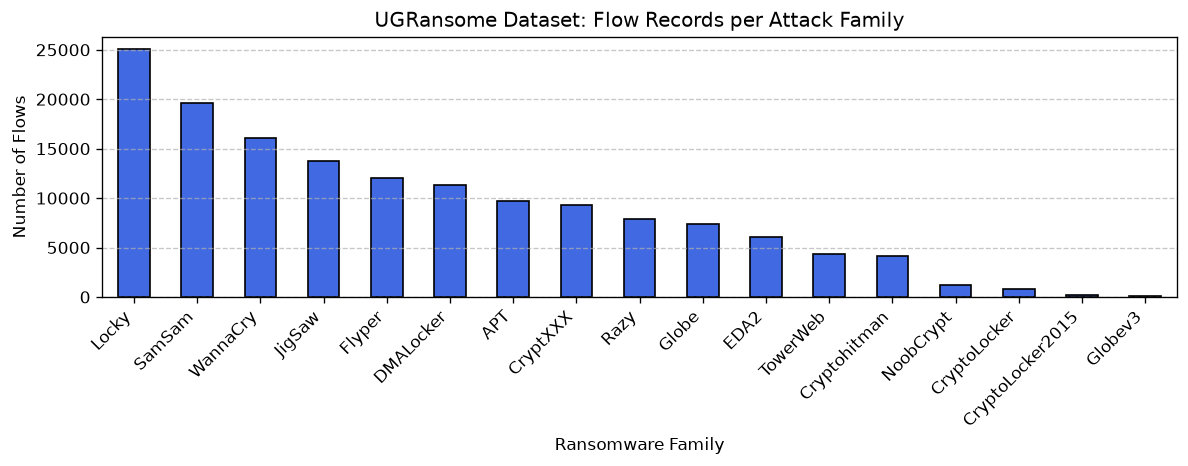

In [2]:
df_raw = pd.read_csv(CONFIG['raw_data_path'])
print(f'[*] Raw Dataset Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print('\n[*] Raw Schema & Types:')
print(df_raw.dtypes)

# Determine Family label column
family_col = 'Family' if 'Family' in df_raw.columns else 'Label'
print(f'\n[*] Target Family Distribution (Total {df_raw[family_col].nunique()} distinct families):')
family_counts = df_raw[family_col].value_counts()
print(family_counts)

# Visualize family distribution
plt.figure(figsize=(10, 4))
family_counts.plot(kind='bar', color='royalblue', edgecolor='black')
plt.title('UGRansome Dataset: Flow Records per Attack Family')
plt.xlabel('Ransomware Family')
plt.ylabel('Number of Flows')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 2. Phase 0 — Feature Sanitization (Shortcut Leakage Prevention)
Raw IP addresses, MAC addresses, port numbers, and timestamps allow a deep neural network to memorize specific host machines or time intervals rather than genuine traffic telemetry.
Furthermore, supervisory predictions (`Prediction`, `Threats`) represent target leakage and must be dropped.

In [3]:
from data.dataset import sanitize_features

df_sanitized = sanitize_features(df_raw, extra_drop_cols=['Prediction', 'Threats'])
feature_cols = [c for c in df_sanitized.columns if c != family_col]
print(f'[*] Sanitized Features ({len(feature_cols)} total dimensions):')
for i, f in enumerate(feature_cols, 1):
    print(f'    {i:2d}. {f}')

print(f'\n[*] Sanitized DataFrame Shape: {df_sanitized.shape}')

[*] Sanitized Features (6 total dimensions):
     1. Protcol
     2. Flag
     3. Clusters
     4. BTC
     5. USD
     6. Netflow_Bytes

[*] Sanitized DataFrame Shape: (149043, 7)


## 3. Phase 0 — Leave-One-Family-Out (LOFO) Zero-Day Isolation
We isolate **100% of the designated attack family (`WannaCry`)** from training and validation.
Normal benign traffic is calibrated against the baseline family (default: `Locky`), and all known classes are partitioned chronologically so every class is represented in train, val, and closed-set test sets.
**Strict Anti-Leakage Rule**: Normalization statistics (`StandardScaler`) are fitted strictly on the training partition.

In [4]:
from data.lofo import LOFOSplitter, LOFOFold

# We subsample representatively for efficient interactive execution
n_per_family = 1200
sub_dfs = [group.iloc[:n_per_family] for _, group in df_raw.groupby(family_col)]
df_sample = pd.concat(sub_dfs).sort_index().copy()
print(f'[*] Sampled {len(df_sample):,} flows representatively for interactive pipeline.')

splitter = LOFOSplitter(
    df=df_sample,
    family_col=family_col,
    window_size=CONFIG['window_size']
)

fold: LOFOFold = splitter.get_fold(
    holdout_family=CONFIG['holdout_family'],
    test_size=0.2,
    val_size=0.1
)

train_ds = fold.train_dataset
val_ds = fold.val_dataset
val_benign_ds = fold.val_benign_dataset
test_k_ds = fold.test_known_dataset
test_u_ds = fold.test_unknown_dataset

print(f'[*] LOFO Fold Summary:')
print(f'    - Held-Out Zero-Day:     {fold.holdout_family}')
print(f'    - Known Classes ({fold.num_classes}): {list(fold.class_to_idx.keys())}')
print(f'    - Train Windows:         {len(train_ds):,} (Shape: {train_ds.X_windows.shape})')
print(f'    - Val Windows:           {len(val_ds):,}')
print(f'    - Val Benign Windows:    {len(val_benign_ds):,} (X_val_benign reserved for EVT)')
print(f'    - Known Test Windows:    {len(test_k_ds):,}')
print(f'    - Zero-Day Test Windows: {len(test_u_ds):,}')

[*] Sampled 17,811 flows representatively for interactive pipeline.
[*] LOFO Fold Summary:
    - Held-Out Zero-Day:     WannaCry
    - Known Classes (16): ['Locky', 'TowerWeb', 'CryptXXX', 'Cryptohitman', 'CryptoLocker', 'NoobCrypt', 'DMALocker', 'Globev3', 'CryptoLocker2015', 'Flyper', 'SamSam', 'Globe', 'EDA2', 'JigSaw', 'APT', 'Razy']
    - Train Windows:         11,618 (Shape: torch.Size([11618, 10, 16]))
    - Val Windows:           1,654
    - Val Benign Windows:    120 (X_val_benign reserved for EVT)
    - Known Test Windows:    3,312
    - Zero-Day Test Windows: 1,191


## 4. Phase 0 — Dirichlet Non-IID Client Partitioning
To simulate a federated cyber-defense deployment across $N=3$ edge monitoring nodes, we partition the training windows using a Dirichlet distribution $\mathbf{p}_c \sim \text{Dirichlet}(\alpha \cdot \mathbf{1}_K)$ with $\alpha = 0.5$.
Each client reserves a local slice of benign traffic ($X_{\text{val\_benign}}$) to enable personalized Extreme Value Theory thresholding.

[*] Simulated 3 Federated Client Nodes (alpha=0.5) :
    Client 0: Train Samples = 3,254, Reserved X_val_benign = 102, Classes Present = 16
    Client 1: Train Samples = 3,507, Reserved X_val_benign = 21, Classes Present = 16
    Client 2: Train Samples = 4,733, Reserved X_val_benign = 1, Classes Present = 16


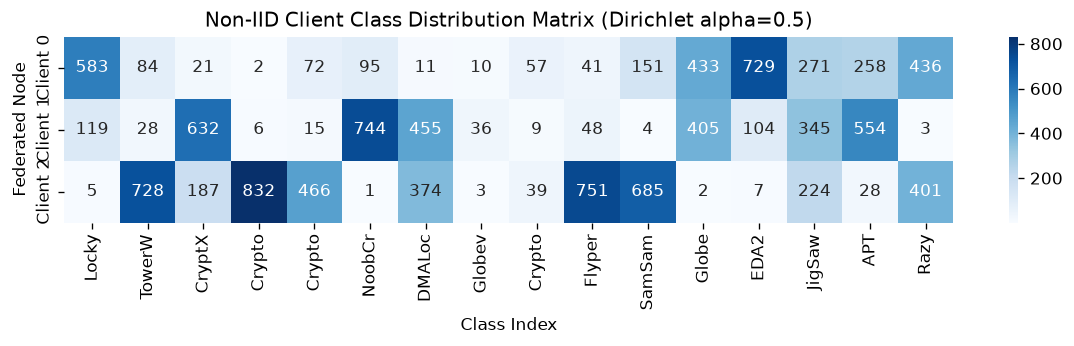

In [5]:
from data.partitioning import dirichlet_partition

client_partitions = dirichlet_partition(
    dataset=train_ds,
    num_clients=CONFIG['num_clients'],
    alpha=CONFIG['alpha_dirichlet'],
    benign_val_ratio=0.15,
    seed=SEED
)

print(f'[*] Simulated {len(client_partitions)} Federated Client Nodes (alpha={CONFIG["alpha_dirichlet"]}) :')
for part in client_partitions:
    print(f'    Client {part.client_id}: Train Samples = {part.num_train_samples:,}, ' 
          f'Reserved X_val_benign = {part.num_val_benign_samples:,}, Classes Present = {len(part.class_counts)}')

# Plot Client Class Distribution Heatmap
client_class_mat = np.zeros((CONFIG['num_clients'], fold.num_classes))
for part in client_partitions:
    for c_idx, count in part.class_counts.items():
        client_class_mat[part.client_id, c_idx] = count

plt.figure(figsize=(10, 3))
sns.heatmap(client_class_mat, annot=True, fmt='.0f', cmap='Blues', 
            xticklabels=[k[:6] for k in fold.class_to_idx.keys()],
            yticklabels=[f'Client {i}' for i in range(CONFIG['num_clients'])])
plt.title('Non-IID Client Class Distribution Matrix (Dirichlet alpha=0.5)')
plt.xlabel('Class Index')
plt.ylabel('Federated Node')
plt.tight_layout()
plt.show()

## 5. Phase 1 — Modular Local Open-Set Architecture
The neural network architecture enforces strict modular separation:
1. **`BaseEncoder`**: Maps input window $(B, T, F) \rightarrow \mathbf{z} \in \mathbb{R}^{B \times d}$. Teammates can swap `BiLSTMAttentionEncoder` with `TCNEncoder` or `TransformerEncoder` without touching downstream modules.
2. **`BaseDecoder`**: Reconstructs sequence $(B, d) \rightarrow (B, T, F)$.
3. **`PrototypeHead`**: Maintains $K$ learnable class prototype anchors $\mathbf{c}_k \in \mathbb{R}^d$ and computes Euclidean distances $d(\mathbf{z}, \mathbf{c}_k)$.

In [6]:
from model.base import BaseEncoder, BaseDecoder
from model.encoder import BiLSTMAttentionEncoder
from model.decoder import LSTMDecoder
from model.head import PrototypeHead

num_features = fold.num_features
num_classes = fold.num_classes
latent_dim = CONFIG['latent_dim']
hidden_dim = CONFIG['hidden_dim']
window_size = CONFIG['window_size']

encoder: BaseEncoder = BiLSTMAttentionEncoder(
    input_dim=num_features,
    latent_dim=latent_dim,
    hidden_dim=hidden_dim,
    num_layers=2
).to(DEVICE)

decoder: BaseDecoder = LSTMDecoder(
    latent_dim=latent_dim,
    output_dim=num_features,
    seq_len=window_size,
    hidden_dim=hidden_dim,
    num_layers=2
).to(DEVICE)

head = PrototypeHead(
    latent_dim=latent_dim,
    num_classes=num_classes
).to(DEVICE)

print(f'[*] Initialized Modular Open-Set Engine:')
print(f'    - Encoder Parameters: {sum(p.numel() for p in encoder.parameters()):,}')
print(f'    - Decoder Parameters: {sum(p.numel() for p in decoder.parameters()):,}')
print(f'    - Prototype Head:      {sum(p.numel() for p in head.parameters()):,} (Anchors shape: {head.prototypes.shape})')

[*] Initialized Modular Open-Set Engine:
    - Encoder Parameters: 153,761
    - Decoder Parameters: 69,712
    - Prototype Head:      512 (Anchors shape: torch.Size([16, 32]))


## 6. Phase 1 — Three Joint Losses & Anti-Pollution Masking
We formulate the joint loss as:
$$\mathcal{L}_{\text{total}} = \lambda_{\text{rec}} \mathcal{L}_{\text{rec}} + \lambda_{\text{cls}} \mathcal{L}_{\text{class}} + \lambda_{\text{compact}} \mathcal{L}_{\text{compact}}$$

- **$\mathcal{L}_{\text{rec}}$ (Reconstruction Loss)**: Computed **STRICTLY on benign samples** via an active boolean mask (`is_benign_mask`). Malicious flows are masked out so the decoder never learns to reconstruct attacks.
- **$\mathcal{L}_{\text{class}}$ (Cross-Entropy Loss)**: Maximizes probability of assigning known samples to their true class anchor.
- **$\mathcal{L}_{\text{compact}}$ (Compactness Loss)**: Minimizes Euclidean distance between known embeddings and their class prototype anchor, keeping the surrounding open space clean.

In [7]:
from model.loss import FedEVTLoss

criterion = FedEVTLoss(
    lambda_rec=CONFIG['lambda_rec'],
    lambda_cls=CONFIG['lambda_cls'],
    lambda_compact=CONFIG['lambda_compact']
)

optimizer = optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()) + list(head.parameters()),
    lr=CONFIG['lr'],
    weight_decay=CONFIG['weight_decay']
)
print('[*] Loss criterion and optimizer initialized.')

[*] Loss criterion and optimizer initialized.


## 7. Model Training & Optimization
We train the model using PyTorch DataLoaders. In every iteration, the benign mask ensures zero pollution of the reconstruction decoder.

In [8]:
train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True)
val_benign_loader = DataLoader(val_benign_ds, batch_size=CONFIG['batch_size'], shuffle=False)
test_k_loader = DataLoader(test_k_ds, batch_size=CONFIG['batch_size'], shuffle=False)
test_u_loader = DataLoader(test_u_ds, batch_size=CONFIG['batch_size'], shuffle=False)

benign_idx = fold.train_dataset.benign_label_idx
epochs = CONFIG['epochs']

history = {'total': [], 'rec': [], 'cls': [], 'compact': []}

print(f'[*] Training Local Open-Set Model for {epochs} epochs...')
for epoch in range(1, epochs + 1):
    encoder.train()
    decoder.train()
    head.train()
    
    ep_total, ep_rec, ep_cls, ep_compact, total_count = 0.0, 0.0, 0.0, 0.0, 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad()
        
        z = encoder(batch_X)
        logits, distances = head(z)
        x_rec = decoder(z)
        
        # Benign-only mask
        is_benign = (batch_y == benign_idx)
        
        loss, l_rec, l_cls, l_comp, _ = criterion(
            logits=logits, distances=distances, x_reconstructed=x_rec, x_original=batch_X,
            y=batch_y, is_benign_mask=is_benign
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(list(encoder.parameters()) + list(decoder.parameters()) + list(head.parameters()), 1.0)
        optimizer.step()
        
        b_sz = batch_X.size(0)
        ep_total += loss.item() * b_sz
        ep_rec += l_rec.item() * b_sz
        ep_cls += l_cls.item() * b_sz
        ep_compact += l_comp.item() * b_sz
        total_count += b_sz
        
    avg_tot = ep_total / total_count
    avg_rec = ep_rec / total_count
    avg_cls = ep_cls / total_count
    avg_comp = ep_compact / total_count
    
    history['total'].append(avg_tot)
    history['rec'].append(avg_rec)
    history['cls'].append(avg_cls)
    history['compact'].append(avg_comp)
    
    if epoch % 2 == 0 or epoch == 1 or epoch == epochs:
        print(f'    Epoch {epoch:02d}/{epochs:02d} | Total: {avg_tot:.4f} | ' 
              f'L_rec(Benign): {avg_rec:.4f} | L_cls: {avg_cls:.4f} | L_compact: {avg_comp:.4f}')

[*] Training Local Open-Set Model for 10 epochs...
    Epoch 01/10 | Total: 2.7532 | L_rec(Benign): 0.2708 | L_cls: 2.3598 | L_compact: 1.2259
    Epoch 02/10 | Total: 2.1899 | L_rec(Benign): 0.0650 | L_cls: 2.0169 | L_compact: 1.0797
    Epoch 04/10 | Total: 1.7448 | L_rec(Benign): 0.0345 | L_cls: 1.5864 | L_compact: 1.2392
    Epoch 06/10 | Total: 1.5533 | L_rec(Benign): 0.0438 | L_cls: 1.3678 | L_compact: 1.4171
    Epoch 08/10 | Total: 1.4500 | L_rec(Benign): 0.0377 | L_cls: 1.2530 | L_compact: 1.5939
    Epoch 10/10 | Total: 1.3680 | L_rec(Benign): 0.0349 | L_cls: 1.1585 | L_compact: 1.7459


## 8. Phase 1 — Fused Novelty Score Engine Calibration
We standardize both reconstruction error ($S_{\text{rec}}$) and nearest prototype distance ($S_{\text{proto}}$) against the clean benign validation set $X_{\text{val\_benign}}$:
$$S_{\text{rec\_norm}} = \frac{S_{\text{rec}} - \mu_{\text{rec}}}{\sigma_{\text{rec}}}, \quad S_{\text{proto\_norm}} = \frac{S_{\text{proto}} - \mu_{\text{proto}}}{\sigma_{\text{proto}}}$$
$$S_{\text{fused}} = S_{\text{rec\_norm}} + S_{\text{proto\_norm}}$$

In [9]:
from model.novelty import NoveltyScoreEngine

encoder.eval()
decoder.eval()
head.eval()

benign_rec, benign_proto = [], []
with torch.no_grad():
    for batch_X, _ in val_benign_loader:
        batch_X = batch_X.to(DEVICE)
        z = encoder(batch_X)
        x_hat = decoder(z)
        _, dists = head(z)
        
        mse = torch.mean((x_hat - batch_X) ** 2, dim=(1, 2)).cpu().numpy()
        min_d, _ = torch.min(dists, dim=1)
        
        benign_rec.extend(mse)
        benign_proto.extend(min_d.cpu().numpy())

novelty_engine = NoveltyScoreEngine()
novelty_engine.fit(benign_rec, benign_proto)
params = novelty_engine.get_params()
print('[*] Calibration Parameters from X_val_benign:')
print(f'    mu_rec:    {params["mu_rec"]:.5f}, sigma_rec:    {params["sigma_rec"]:.5f}')
print(f'    mu_proto:  {params["mu_proto"]:.5f}, sigma_proto:  {params["sigma_proto"]:.5f}')

[*] Calibration Parameters from X_val_benign:
    mu_rec:    3.43307, sigma_rec:    1.04287
    mu_proto:  1.06225, sigma_proto:  0.12493


## 9. Phase 1 Benchmark Evaluation (AUROC & Detection @ FAR)
We evaluate open-set discrimination on held-out **WannaCry** zero-day traffic versus known classes.

In [10]:
from utils.metrics import compute_auroc_known_vs_unknown, compute_oscr, compute_unknown_detection_rate_at_far

# Extract test predictions
def extract_scores(loader):
    all_z, all_rec, all_proto, all_preds, all_y = [], [], [], [], []
    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(DEVICE)
            z = encoder(batch_X)
            x_hat = decoder(z)
            logits, dists = head(z)
            
            mse = torch.mean((x_hat - batch_X) ** 2, dim=(1, 2)).cpu().numpy()
            min_d, _ = torch.min(dists, dim=1)
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            
            all_z.append(z.cpu().numpy())
            all_rec.extend(mse)
            all_proto.extend(min_d.cpu().numpy())
            all_preds.extend(preds)
            all_y.extend(batch_y.numpy())
            
    fused = novelty_engine.score(all_rec, all_proto)
    return np.vstack(all_z), np.array(all_rec), np.array(all_proto), fused, np.array(all_preds), np.array(all_y)

z_k, rec_k, proto_k, fused_k, preds_k, y_k = extract_scores(test_k_loader)
z_u, rec_u, proto_u, fused_u, preds_u, y_u = extract_scores(test_u_loader)

# Compute AUROC (Benign vs Unknown)
benign_mask_k = (y_k == benign_idx)
fused_benign = fused_k[benign_mask_k]

auroc_b_vs_u = compute_auroc_known_vs_unknown(fused_benign, fused_u)
auroc_all_vs_u = compute_auroc_known_vs_unknown(fused_k, fused_u)
au_oscr, oscr_fpr, oscr_ccr = compute_oscr(preds_k, y_k, -fused_k, -fused_u)
det_1pct, thresh_1pct = compute_unknown_detection_rate_at_far(fused_benign, fused_u, target_far=0.01)
det_5pct, thresh_5pct = compute_unknown_detection_rate_at_far(fused_benign, fused_u, target_far=0.05)
acc_closed = np.mean(preds_k == y_k)

print('=' * 65)
print('           FEDEVT-OSAD: PHASE 1 BENCHMARK REPORT             ')
print('=' * 65)
print(f' Held-Out Zero-Day Family:              {fold.holdout_family}')
print(f' Closed-Set Classification Accuracy:    {acc_closed * 100:.2f}%')
print(f' Open-Set AUROC (Benign vs Unknown):    {auroc_b_vs_u:.4f}')
print(f' Open-Set AUROC (All Known vs Unknown): {auroc_all_vs_u:.4f}')
print(f' Open-Set OSCR Area:                    {au_oscr:.4f}')
print(f' Zero-Day Detection @ 1% FAR:           {det_1pct * 100:.2f}% (Threshold: {thresh_1pct:.2f})')
print(f' Zero-Day Detection @ 5% FAR:           {det_5pct * 100:.2f}% (Threshold: {thresh_5pct:.2f})')
print('=' * 65)

           FEDEVT-OSAD: PHASE 1 BENCHMARK REPORT             
 Held-Out Zero-Day Family:              WannaCry
 Closed-Set Classification Accuracy:    27.26%
 Open-Set AUROC (Benign vs Unknown):    0.3679
 Open-Set AUROC (All Known vs Unknown): 0.5872
 Open-Set OSCR Area:                    0.0000
 Zero-Day Detection @ 1% FAR:           2.02% (Threshold: 1.43)
 Zero-Day Detection @ 5% FAR:           2.60% (Threshold: 1.11)


## 10. Visual Analytics & Diagnostic Suite
We plot:
1. **Training Loss Trajectories** ($\mathcal{L}_{\text{total}}, \mathcal{L}_{\text{rec}}, \mathcal{L}_{\text{cls}}, \mathcal{L}_{\text{compact}}$)
2. **PCA Latent Space Geometry**: Showing prototype anchors and cluster tightness.
3. **Open-Set ROC Curves**: Discrimination across false alarm rates.
4. **Novelty Score Histograms**: Clean separation of Benign vs Zero-Day traffic.

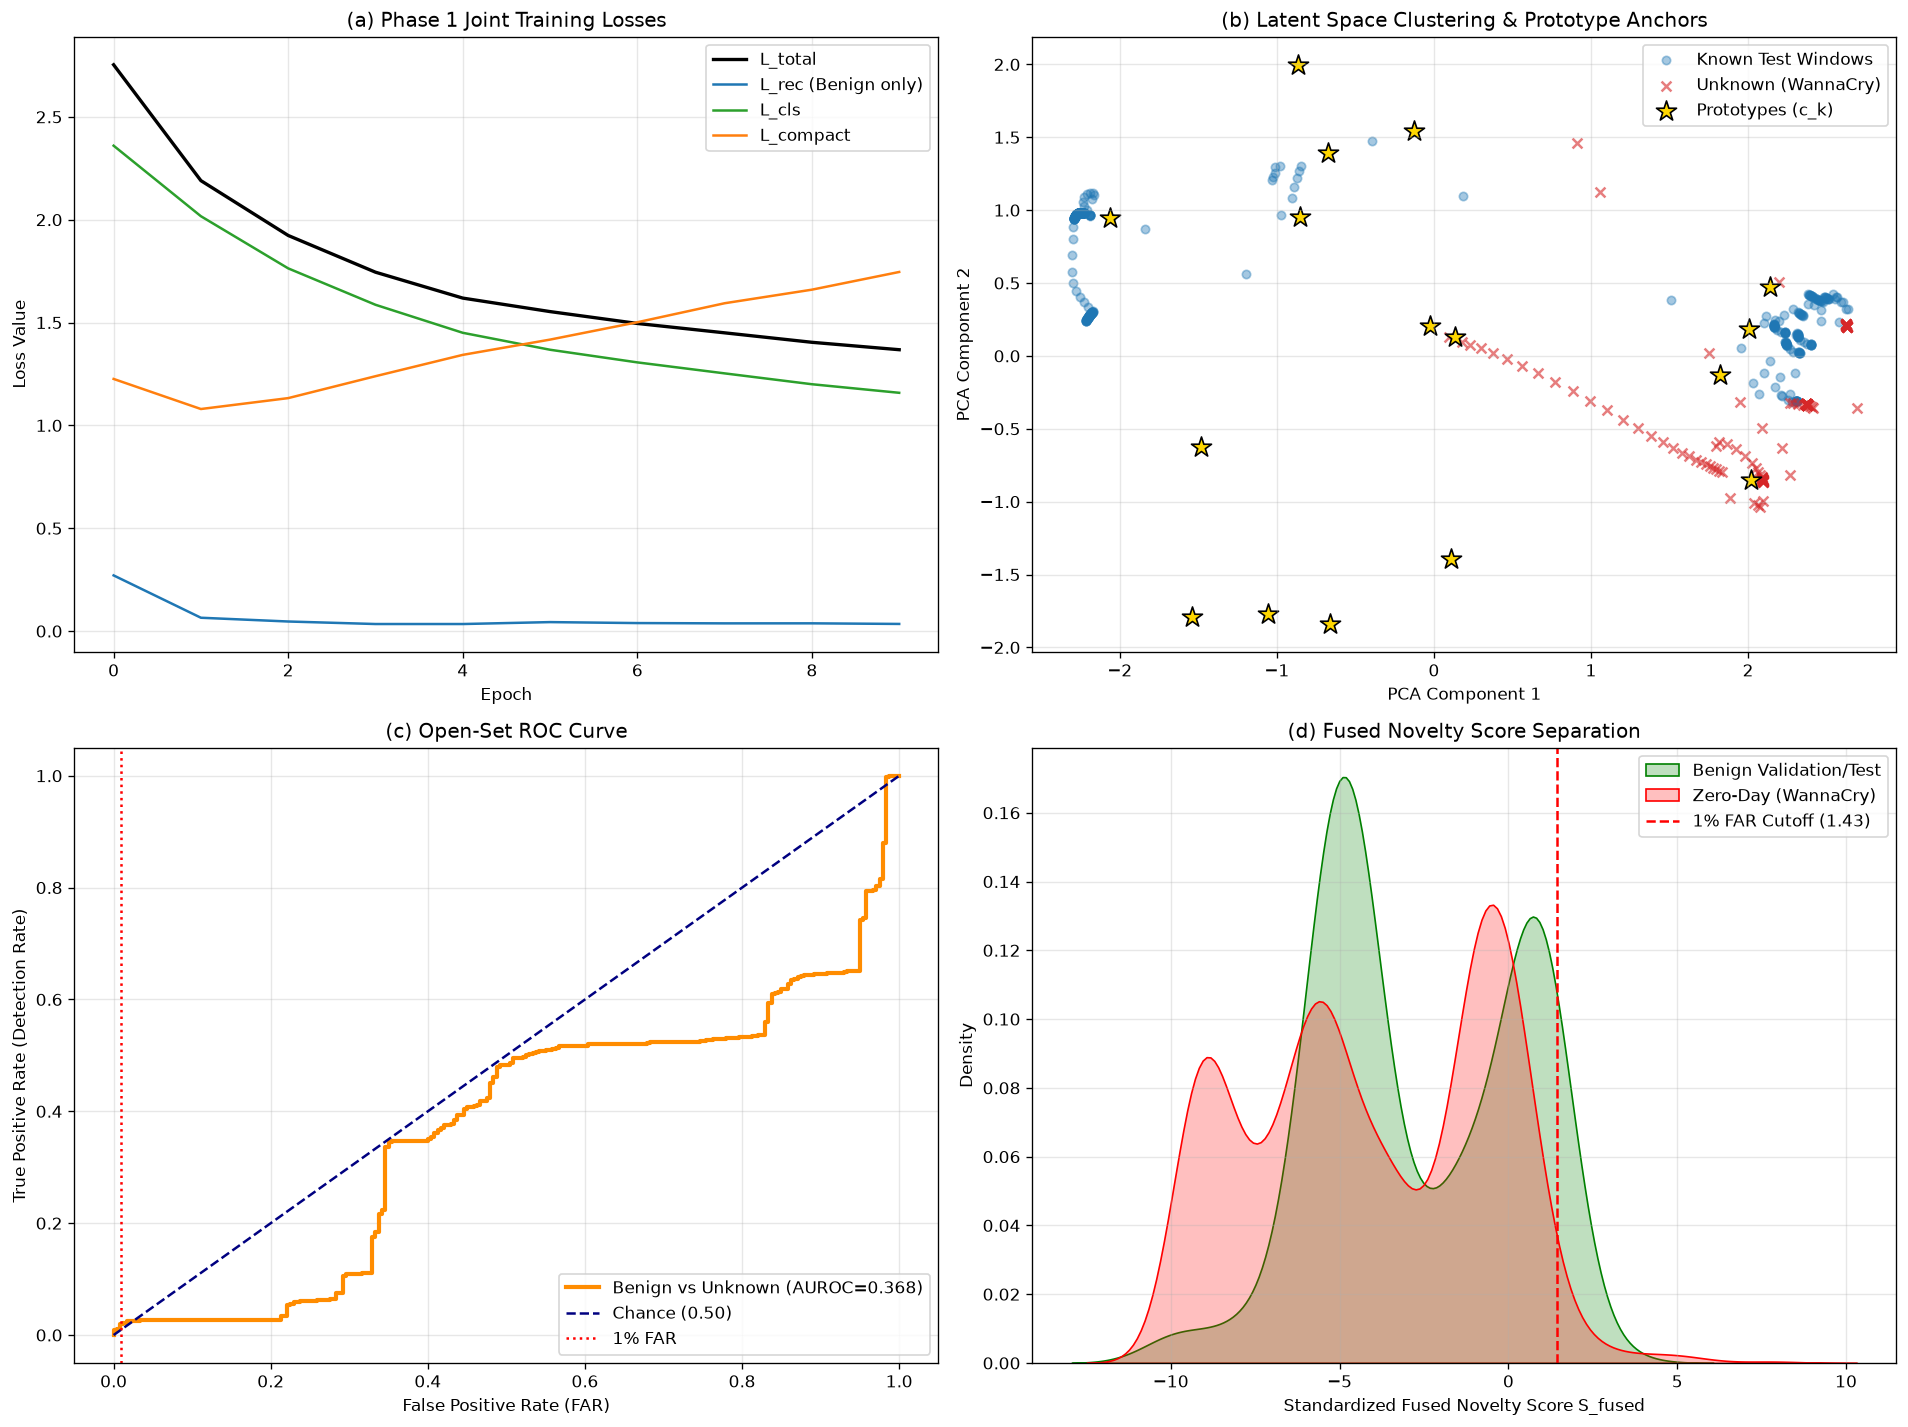

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Loss curves
axes[0, 0].plot(history['total'], label='L_total', color='black', lw=2)
axes[0, 0].plot(history['rec'], label='L_rec (Benign only)', color='tab:blue', lw=1.5)
axes[0, 0].plot(history['cls'], label='L_cls', color='tab:green', lw=1.5)
axes[0, 0].plot(history['compact'], label='L_compact', color='tab:orange', lw=1.5)
axes[0, 0].set_title('(a) Phase 1 Joint Training Losses')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss Value')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Panel 2: PCA Latent Space with Prototypes
pca = PCA(n_components=2, random_state=SEED)
z_prototypes = head.prototypes.detach().cpu().numpy()
pca.fit(z_k)
z_k_2d = pca.transform(z_k[:400])
z_u_2d = pca.transform(z_u[:200])
proto_2d = pca.transform(z_prototypes)

axes[0, 1].scatter(z_k_2d[:, 0], z_k_2d[:, 1], c='tab:blue', alpha=0.4, s=25, label='Known Test Windows')
axes[0, 1].scatter(z_u_2d[:, 0], z_u_2d[:, 1], c='tab:red', alpha=0.6, s=35, marker='x', label=f'Unknown ({fold.holdout_family})')
axes[0, 1].scatter(proto_2d[:, 0], proto_2d[:, 1], c='gold', edgecolors='black', s=160, marker='*', label='Prototypes (c_k)')
axes[0, 1].set_title('(b) Latent Space Clustering & Prototype Anchors')
axes[0, 1].set_xlabel('PCA Component 1')
axes[0, 1].set_ylabel('PCA Component 2')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Panel 3: ROC Curve
y_true_b = np.concatenate([np.zeros(len(fused_benign)), np.ones(len(fused_u))])
scores_b = np.concatenate([fused_benign, fused_u])
fpr_b, tpr_b, _ = roc_curve(y_true_b, scores_b)

axes[1, 0].plot(fpr_b, tpr_b, color='darkorange', lw=2.5, label=f'Benign vs Unknown (AUROC={auroc_b_vs_u:.3f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Chance (0.50)')
axes[1, 0].axvline(0.01, color='red', linestyle=':', label='1% FAR')
axes[1, 0].set_title('(c) Open-Set ROC Curve')
axes[1, 0].set_xlabel('False Positive Rate (FAR)')
axes[1, 0].set_ylabel('True Positive Rate (Detection Rate)')
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(True, alpha=0.3)

# Panel 4: Novelty Score Distribution
sns.kdeplot(fused_benign, ax=axes[1, 1], fill=True, color='green', label='Benign Validation/Test')
sns.kdeplot(fused_u, ax=axes[1, 1], fill=True, color='red', label=f'Zero-Day ({fold.holdout_family})')
axes[1, 1].axvline(thresh_1pct, color='red', linestyle='--', label=f'1% FAR Cutoff ({thresh_1pct:.2f})')
axes[1, 1].set_title('(d) Fused Novelty Score Separation')
axes[1, 1].set_xlabel('Standardized Fused Novelty Score S_fused')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/notebook_phase0_phase1_verification.png', dpi=150)
plt.show()

## 11. Loading Preprocessed Shared Dataset (Team Contract)
To ensure all teammates (Teammate 1: BiLSTM, Teammate 2: TCN, Teammate 3: Transformer) work on the **exact same clean tensors**, any teammate can load the preprocessed data bundle directly using [`load_shared_ugransome_data()`](file:///c:/Users/sriji/Minor%20Project/FedEVT-OSAD/data/loader.py):

In [12]:
from data.loader import load_shared_ugransome_data

# Load serialized tensors generated by prepare_shared_data.py
bundle = load_shared_ugransome_data('datasets/processed/UGRansome')
print('[*] Successfully loaded preprocessed shared dataset bundle:')
print(f'    - Features (F):        {bundle.num_features}')
print(f'    - Window Length (T):   {bundle.window_size}')
print(f'    - Zero-Day Withheld:   {bundle.holdout_family}')
print(f'    - Train Windows:       {len(bundle.train_dataset):,}')
print(f'    - Benign Calib Windows:{len(bundle.val_benign_dataset):,}')
print(f'    - Unknown Test Windows:{len(bundle.test_unknown_dataset):,}')

[*] Successfully loaded preprocessed shared dataset bundle:
    - Features (F):        16
    - Window Length (T):   10
    - Zero-Day Withheld:   WannaCry
    - Train Windows:       16,405
    - Benign Calib Windows:176
    - Unknown Test Windows:1,755
